#### Imports

In [3]:
import torch
from torchvision import datasets
import numpy as np
import matplotlib.pyplot as plt

from geometry_mnist.paths import ROOT
from geometry_mnist.datagen import write_data

#### Classical MNIST

targets.shape=(70000, 1), data.shape=(70000, 28, 28)
> writing dataset mnist.h5


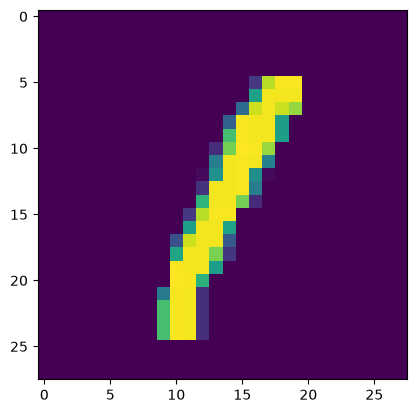

In [4]:
train = datasets.MNIST(
    root = ROOT / "data/tempdl",
    train = True,
)
valid = datasets.MNIST(
    root = ROOT / "data/tempdl",
    train = False,
)

data = np.concat([train.data.numpy(), valid.data.numpy()])
targets = np.concat([train.targets.numpy(), valid.targets.numpy()])[:, None]

print(f"{targets.shape=}, {data.shape=}")
_ = plt.imshow(data[np.random.randint(0, 100)])

write_data(
    dataset_name = "mnist.h5",
    data = data,
    targets = targets,
)

#### EMNIST 

this is basically the analogue to mnist but with letters. has a class balanced letter version. for some reason all the images are transposed

targets.shape=(124800, 1), data.shape=(124800, 28, 28)


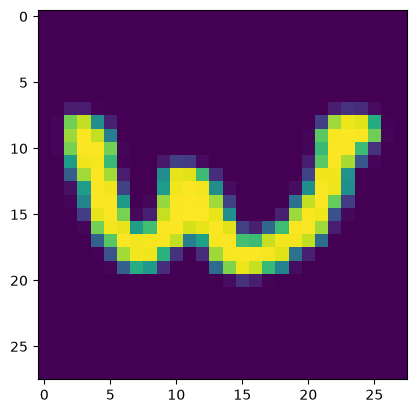

In [4]:
entire_dataset = datasets.EMNIST(
    root = ROOT / "data/tempdl",
    split = "letters",
    download = True,
)

data = np.transpose(entire_dataset.data.numpy(), axes=(0, 2, 1))
targets = entire_dataset.targets.numpy()[:, None]

print(f"{targets.shape=}, {data.shape=}")
_ = plt.imshow(data[np.random.randint(0, 100)])

#### KMNIST

basically mnist but with small hiragana characters. same size same idea also 10 classe but more complicated shape. Probably a bit too finnicky

targets.shape=(70000, 1), data.shape=(70000, 28, 28)


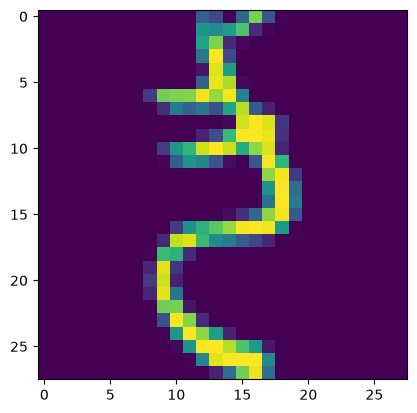

In [35]:
# needs a weird download certificate fix
import truststore
truststore.inject_into_ssl()

train = datasets.KMNIST(
    root = ROOT / "data/tempdl",
    train = True,
    download = True,
)
valid = datasets.KMNIST(
    root = ROOT / "data/tempdl",
    train = False,
    download = True,
)

data = np.concat([train.data.numpy(), valid.data.numpy()])
targets = np.concat([train.targets.numpy(), valid.targets.numpy()])[:, None]

print(f"{targets.shape=}, {data.shape=}")
_ = plt.imshow(data[np.random.randint(0, 100)])


#### Omniglot

loots of different characters, but only 20 per class. Could be interesting for more variety

In [42]:
# has two weird set with background and not background 
train = datasets.Omniglot(
    root = ROOT / "data/tempdl",
    background = True,
    download = True
)

images = np.stack([np.array(img) for img, _ in train])   # (19280, 105, 105), uint8
labels = np.array([label for _, label in train])          # (19280,)


labels.shape=(19280,), images.shape=(19280, 105, 105)


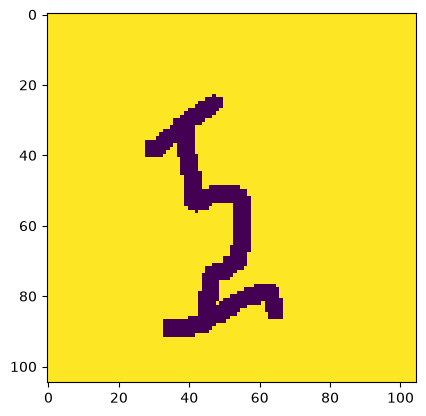

In [58]:
print(f"{labels.shape=}, {images.shape=}")
_ = plt.imshow(images[np.random.randint(0, 100)])

#### Quick Draw

this is kinda interesting. 300-400 classes of hand drawn black line images of totally ranndom things. can get quite messy but there is a 28x28 version. quiiiite a lot of imgs! could be something to really stress test. has an email for showing projects with it :)